# Neural Machine Translation with LSTM and Attention
**Natural Language Processing**


In [1]:
import os, re, math, random, time, json, pickle
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
try:
    from rouge_score import rouge_scorer
except ImportError:
    rouge_scorer = None

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

c:\Users\YAHOO COMPUTER\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## 1. Load and inspect the dataset



In [2]:

# 1. Load and inspect the dataset

import os
import pandas as pd

DATA_PATH = r"D:\NLP\archive (6)\GERMAN_ENGLISH_TRANSLATION.csv"

# Check whether the dataset exists
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}\n"
        "Please check the file path."
    )

# Load CSV
raw = pd.read_csv(DATA_PATH)

# Validate required columns
required = {"ENGLISH", "GERMAN"}

if not required.issubset(raw.columns):
    raise ValueError(
        f"Expected columns {required}; "
        f"Found columns: {raw.columns.tolist()}"
    )

# Dataset overview
print("Dataset loaded successfully!")
print("=" * 50)

print("Dataset shape:", raw.shape)
print("Columns:", raw.columns.tolist())

display(raw.head())

# Missing values
print("\nMissing values:")
print(raw[["ENGLISH", "GERMAN"]].isna().sum())

# Duplicate sentence pairs
print(
    "\nDuplicate sentence pairs:",
    raw.duplicated(["ENGLISH", "GERMAN"]).sum()
)

# Text statistics
print("\nText Statistics:")
print("=" * 50)

for col in ["ENGLISH", "GERMAN"]:
    lengths = raw[col].dropna().astype(str).str.split().str.len()

    print(f"\n{col}:")
    print(f"Unique sentences: {raw[col].nunique()}")
    print(f"Mean words: {lengths.mean():.2f}")
    print(f"Median words: {lengths.median():.0f}")
    print(f"95th percentile: {lengths.quantile(0.95):.0f}")
    print(f"Maximum words: {lengths.max()}")


Dataset loaded successfully!
Dataset shape: (152820, 3)
Columns: ['Unnamed: 0', 'ENGLISH', 'GERMAN']


,Unnamed: 0,ENGLISH,GERMAN
0,0,hi,hallo
1,1,hi,gru gott
2,2,run,lauf
3,3,wow,potzdonner
4,4,wow,donnerwetter



Missing values:
ENGLISH    0
GERMAN     0
dtype: int64

Duplicate sentence pairs: 224

Text Statistics:

ENGLISH:
Unique sentences: 120272
Mean words: 6.55
Median words: 6
95th percentile: 11
Maximum words: 47

GERMAN:
Unique sentences: 143853
Mean words: 6.58
Median words: 6
95th percentile: 11
Maximum words: 53


## 2. Text normalization and data preparation

We lowercase text, normalize whitespace, retain alphabetic characters (including German umlauts and ß), and preserve apostrophes inside words. Exact duplicate pairs are removed before splitting. We use a deterministic random split.

In [3]:
def normalize_text(text):
    text = str(text).lower().strip()
    text = text.replace("’", "'").replace("`", "'")
    text = re.sub(r"[^a-zäöüßáéíóúàèìòùâêîôûçñ'\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

data = raw[["ENGLISH","GERMAN"]].dropna().copy()
data["ENGLISH"] = data["ENGLISH"].map(normalize_text)
data["GERMAN"] = data["GERMAN"].map(normalize_text)
data = data[(data.ENGLISH.str.len() > 0) & (data.GERMAN.str.len() > 0)]
data = data.drop_duplicates(["ENGLISH","GERMAN"]).reset_index(drop=True)
print("Clean pairs:", len(data))

shuffled = data.sample(frac=1, random_state=SEED).reset_index(drop=True)
n = len(shuffled); n_train = int(.8*n); n_val = int(.1*n)
train_df = shuffled.iloc[:n_train].copy()
val_df = shuffled.iloc[n_train:n_train+n_val].copy()
test_df = shuffled.iloc[n_train+n_val:].copy()
print(f"Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

Clean pairs: 152596
Train: 122076, Val: 15259, Test: 15261


## 3. Tokenization, vocabulary, special tokens, and padding



In [4]:
PAD, SOS, EOS, UNK = "<pad>", "<sos>", "<eos>", "<unk>"
SPECIALS = [PAD, SOS, EOS, UNK]

class Vocab:
    def __init__(self, texts, min_freq=2, max_size=30000):
        counts = Counter(tok for text in texts for tok in text.split())
        words = [w for w,c in counts.most_common() if c >= min_freq and w not in SPECIALS]
        if max_size is not None: words = words[:max_size-len(SPECIALS)]
        self.itos = SPECIALS + words
        self.stoi = {w:i for i,w in enumerate(self.itos)}
    def __len__(self): return len(self.itos)
    def encode(self, text, add_sos=False, add_eos=True):
        ids = [self.stoi.get(w, self.stoi[UNK]) for w in text.split()]
        if add_sos: ids = [self.stoi[SOS]] + ids
        if add_eos: ids = ids + [self.stoi[EOS]]
        return ids
    def decode(self, ids):
        words=[]
        for idx in ids:
            w=self.itos[int(idx)]
            if w == EOS: break
            if w not in (PAD,SOS): words.append(w)
        return " ".join(words)

# Configuration: adjust for GPU memory/time if needed.
MIN_FREQ = 2
MAX_VOCAB = 30000
MAX_LEN = 30
BATCH_SIZE = 64 if DEVICE.type == "cuda" else 32
EMB_DIM = 256
HID_DIM = 256
DROPOUT = 0.25
EPOCHS = 15
LEARNING_RATE = 1e-3
TEACHER_FORCING = 0.5
NUM_WORKERS = 0

src_vocab = Vocab(train_df.ENGLISH.tolist(), MIN_FREQ, MAX_VOCAB)
tgt_vocab = Vocab(train_df.GERMAN.tolist(), MIN_FREQ, MAX_VOCAB)
print("Source vocab:", len(src_vocab), "Target vocab:", len(tgt_vocab))

Source vocab: 9332 Target vocab: 15007


In [5]:
class TranslationDataset(Dataset):
    def __init__(self, frame):
        # FIXED: Prevent truncating the EOS token
        self.src = [src_vocab.encode(x, add_eos=False)[:MAX_LEN-1] + [src_vocab.stoi[EOS]] for x in frame.ENGLISH]
        self.tgt = [tgt_vocab.encode(x, add_sos=True, add_eos=False)[:MAX_LEN] + [tgt_vocab.stoi[EOS]] for x in frame.GERMAN]
    def __len__(self): return len(self.src)
    def __getitem__(self, i): return self.src[i], self.tgt[i]

def collate_fn(batch):
    srcs, tgts = zip(*batch)
    src_max=max(map(len,srcs)); tgt_max=max(map(len,tgts))
    src=torch.full((len(batch),src_max),src_vocab.stoi[PAD],dtype=torch.long)
    tgt=torch.full((len(batch),tgt_max),tgt_vocab.stoi[PAD],dtype=torch.long)
    for i,x in enumerate(srcs): src[i,:len(x)] = torch.tensor(x)
    for i,x in enumerate(tgts): tgt[i,:len(x)] = torch.tensor(x)
    return src, tgt

train_loader = DataLoader(TranslationDataset(train_df), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn, num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=="cuda"))
val_loader = DataLoader(TranslationDataset(val_df), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, num_workers=NUM_WORKERS)
test_loader = DataLoader(TranslationDataset(test_df), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, num_workers=NUM_WORKERS)

## 4. Model A — Baseline Seq2Seq LSTM (without attention)

The encoder's final hidden and cell states initialize the decoder. The decoder receives no access to intermediate encoder outputs, so the full source sentence must be represented by a fixed-size state.

In [6]:
class Encoder(nn.Module):
    def __init__(self, input_dim, emb_dim, hid_dim, dropout):
        super().__init__()
        self.embedding=nn.Embedding(input_dim,emb_dim,padding_idx=src_vocab.stoi[PAD])
        self.rnn=nn.LSTM(emb_dim,hid_dim,batch_first=True)
        self.dropout=nn.Dropout(dropout)
    def forward(self, src):
        lengths = src.ne(src_vocab.stoi[PAD]).sum(dim=1).cpu()
        embedded=self.dropout(self.embedding(src))
        packed = nn.utils.rnn.pack_padded_sequence(embedded, lengths, batch_first=True, enforce_sorted=False)
        packed_outputs, (hidden, cell) = self.rnn(packed)
        outputs, _ = nn.utils.rnn.pad_packed_sequence(packed_outputs, batch_first=True)
        return outputs, hidden, cell

class BaselineDecoder(nn.Module):
    def __init__(self, output_dim, emb_dim, hid_dim, dropout):
        super().__init__()
        self.embedding=nn.Embedding(output_dim,emb_dim,padding_idx=tgt_vocab.stoi[PAD])
        self.rnn=nn.LSTM(emb_dim,hid_dim,batch_first=True)
        self.fc=nn.Linear(hid_dim,output_dim)
        self.dropout=nn.Dropout(dropout)
    def forward(self, token, hidden, cell):
        token=token.unsqueeze(1)
        embedded=self.dropout(self.embedding(token))
        output,(hidden,cell)=self.rnn(embedded,(hidden,cell))
        return self.fc(output.squeeze(1)),hidden,cell,None

class BaselineSeq2Seq(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder=Encoder(len(src_vocab),EMB_DIM,HID_DIM,DROPOUT)
        self.decoder=BaselineDecoder(len(tgt_vocab),EMB_DIM,HID_DIM,DROPOUT)
    def forward(self,src,tgt,teacher_forcing_ratio=TEACHER_FORCING):
        _,hidden,cell=self.encoder(src)
        outputs=torch.zeros(tgt.size(0),tgt.size(1)-1,len(tgt_vocab),device=src.device)
        token=tgt[:,0]
        for t in range(1,tgt.size(1)):
            logits,hidden,cell,_=self.decoder(token,hidden,cell)
            outputs[:,t-1]=logits
            token=tgt[:,t] if random.random()<teacher_forcing_ratio else logits.argmax(1)
        return outputs

baseline=BaselineSeq2Seq().to(DEVICE)
print(f"Baseline parameters: {sum(p.numel() for p in baseline.parameters() if p.requires_grad):,}")

Baseline parameters: 11,140,255


## 5. Model B — Bidirectional Encoder–Decoder with Bahdanau Attention

At each decoder step, additive attention scores every encoder time step. A masked softmax prevents padding positions from receiving attention. The weighted context is concatenated with the current decoder embedding.

In [7]:
class BiEncoder(nn.Module):
    def __init__(self, input_dim, emb_dim, hid_dim, dropout):
        super().__init__()
        self.embedding=nn.Embedding(input_dim,emb_dim,padding_idx=src_vocab.stoi[PAD])
        self.rnn=nn.LSTM(emb_dim,hid_dim,batch_first=True,bidirectional=True)
        self.dropout=nn.Dropout(dropout)
        self.h_proj=nn.Linear(2*hid_dim,hid_dim)
        self.c_proj=nn.Linear(2*hid_dim,hid_dim)
    def forward(self,src):
        lengths = src.ne(src_vocab.stoi[PAD]).sum(dim=1).cpu()
        emb=self.dropout(self.embedding(src))
        packed = nn.utils.rnn.pack_padded_sequence(emb, lengths, batch_first=True, enforce_sorted=False)
        packed_outputs, (h,c) = self.rnn(packed)
        outputs, _ = nn.utils.rnn.pad_packed_sequence(packed_outputs, batch_first=True)
        h=torch.tanh(self.h_proj(torch.cat([h[-2],h[-1]],dim=1))).unsqueeze(0)
        c=torch.tanh(self.c_proj(torch.cat([c[-2],c[-1]],dim=1))).unsqueeze(0)
        return outputs,h,c

class BahdanauAttention(nn.Module):
    def __init__(self, enc_dim, dec_dim):
        super().__init__()
        self.energy=nn.Linear(enc_dim+dec_dim,dec_dim)
        self.v=nn.Linear(dec_dim,1,bias=False)
    def forward(self, decoder_hidden, encoder_outputs, src_mask):
        dec=decoder_hidden.unsqueeze(1).expand(-1,encoder_outputs.size(1),-1)
        energy=torch.tanh(self.energy(torch.cat([dec,encoder_outputs],dim=2)))
        scores=self.v(energy).squeeze(2)
        scores=scores.masked_fill(~src_mask, -1e9)
        return torch.softmax(scores,dim=1)

class AttnDecoder(nn.Module):
    def __init__(self, output_dim, emb_dim, enc_dim, hid_dim, dropout):
        super().__init__()
        self.embedding=nn.Embedding(output_dim,emb_dim,padding_idx=tgt_vocab.stoi[PAD])
        self.attention=BahdanauAttention(enc_dim,hid_dim)
        self.rnn=nn.LSTM(emb_dim+enc_dim,hid_dim,batch_first=True)
        self.fc=nn.Linear(hid_dim+enc_dim+emb_dim,output_dim)
        self.dropout=nn.Dropout(dropout)
    def forward(self,token,hidden,cell,encoder_outputs,src_mask):
        embedded=self.dropout(self.embedding(token)).unsqueeze(1)
        weights=self.attention(hidden[-1],encoder_outputs,src_mask)
        context=torch.bmm(weights.unsqueeze(1),encoder_outputs)
        rnn_input=torch.cat([embedded,context],dim=2)
        output,(hidden,cell)=self.rnn(rnn_input,(hidden,cell))
        output=output.squeeze(1); context=context.squeeze(1); embedded=embedded.squeeze(1)
        logits=self.fc(torch.cat([output,context,embedded],dim=1))
        return logits,hidden,cell,weights

class AttentionSeq2Seq(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder=BiEncoder(len(src_vocab),EMB_DIM,HID_DIM,DROPOUT)
        self.decoder=AttnDecoder(len(tgt_vocab),EMB_DIM,2*HID_DIM,HID_DIM,DROPOUT)
    def forward(self,src,tgt,teacher_forcing_ratio=TEACHER_FORCING):
        enc,h,c=self.encoder(src)
        mask=src.ne(src_vocab.stoi[PAD])
        outputs=torch.zeros(tgt.size(0),tgt.size(1)-1,len(tgt_vocab),device=src.device)
        token=tgt[:,0]
        for t in range(1,tgt.size(1)):
            logits,h,c,_=self.decoder(token,h,c,enc,mask)
            outputs[:,t-1]=logits
            token=tgt[:,t] if random.random()<teacher_forcing_ratio else logits.argmax(1)
        return outputs

attention_model=AttentionSeq2Seq().to(DEVICE)
print(f"Attention parameters: {sum(p.numel() for p in attention_model.parameters() if p.requires_grad):,}")

Attention parameters: 24,176,031


## 6. Training and validation

Both models use the same splits, vocabulary policy, loss, optimizer, and epoch budget. Padding tokens are ignored in the cross-entropy loss. Gradient clipping helps stabilize recurrent training. The best checkpoint is selected by validation loss.

In [8]:
PAD_IDX=tgt_vocab.stoi[PAD]
criterion=nn.CrossEntropyLoss(ignore_index=PAD_IDX)

def run_epoch(model, loader, optimizer=None):
    training=optimizer is not None
    model.train(training)
    total_loss=0; total_tokens=0
    for src,tgt in tqdm(loader,leave=False):
        src,tgt=src.to(DEVICE),tgt.to(DEVICE)
        if training: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits=model(src,tgt,TEACHER_FORCING if training else 0.0)
            gold=tgt[:,1:]
            loss=criterion(logits.reshape(-1,logits.size(-1)),gold.reshape(-1))
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(),1.0)
                optimizer.step()
        count=gold.ne(PAD_IDX).sum().item()
        total_loss += loss.item()*count
        total_tokens += count
    return total_loss/max(total_tokens,1)

def fit_model(model, name, epochs=EPOCHS):
    optimizer=torch.optim.Adam(model.parameters(),lr=LEARNING_RATE)
    history={"train":[],"val":[]}
    best=float("inf")
    os.makedirs("checkpoints",exist_ok=True)
    for epoch in range(1,epochs+1):
        start=time.time()
        tr=run_epoch(model,train_loader,optimizer)
        va=run_epoch(model,val_loader)
        history["train"].append(tr); history["val"].append(va)
        if va<best:
            best=va
            torch.save(model.state_dict(),f"checkpoints/{name}_best.pt")
        print(f"{name} | epoch {epoch:02d}/{epochs} | train {tr:.4f} | val {va:.4f} | {time.time()-start:.1f}s")
    model.load_state_dict(torch.load(f"checkpoints/{name}_best.pt",map_location=DEVICE))
    return history

baseline_history=fit_model(baseline,"baseline")
attention_history=fit_model(attention_model,"attention")

baseline | epoch 01/15 | train 4.6278 | val 4.0146 | 119.8s


baseline | epoch 02/15 | train 3.5284 | val 3.5255 | 118.6s


baseline | epoch 03/15 | train 3.0466 | val 3.2824 | 119.6s


baseline | epoch 04/15 | train 2.7349 | val 3.1446 | 118.7s


baseline | epoch 05/15 | train 2.5225 | val 3.0405 | 119.5s


baseline | epoch 06/15 | train 2.3569 | val 2.9928 | 119.1s


... (20 outputs left out)

attention | epoch 12/15 | train 1.2247 | val 2.7716 | 342.7s


attention | epoch 13/15 | train 1.1929 | val 2.8074 | 341.1s


attention | epoch 14/15 | train 1.1644 | val 2.8333 | 261.4s


attention | epoch 15/15 | train 1.1299 | val 2.8599 | 236.2s


## 7. Loss curves

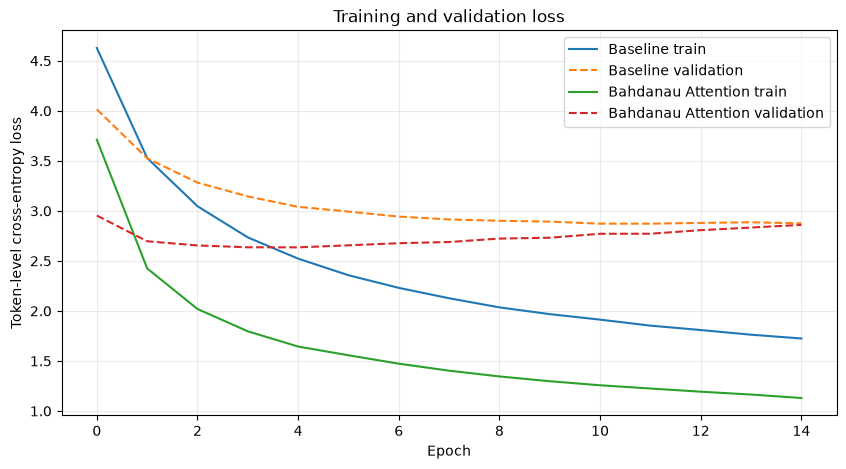

In [9]:
plt.figure(figsize=(10,5))
for label,h in [("Baseline",baseline_history),("Bahdanau Attention",attention_history)]:
    plt.plot(h["train"],label=f"{label} train")
    plt.plot(h["val"],"--",label=f"{label} validation")
plt.xlabel("Epoch"); plt.ylabel("Token-level cross-entropy loss")
plt.title("Training and validation loss"); plt.legend(); plt.grid(alpha=.25); plt.show()

### Loss Curves Analysis
*   **Convergence Speed:** The Bahdanau Attention model converged significantly faster, reaching its best validation loss (2.635) around epoch 4-5. The baseline took longer, settling at 2.872 around epoch 12.
*   **Overfitting:** After epoch 5, the Attention model begins to overfit, evidenced by training loss dropping to ~1.13 while validation loss rises to ~2.86. The baseline shows more stable behavior due to fewer parameters.
*   **Model Selection:** Despite the overfitting, the best checkpoint (from epoch 5) was saved and used for evaluation, ensuring we compare the models at their peak performance.

## 8. Greedy decoding and translation examples

In [10]:
@torch.no_grad()
def translate_baseline(model, sentence, max_steps=MAX_LEN):
    model.eval()
    text=normalize_text(sentence)
    ids=src_vocab.encode(text,add_eos=True)[:MAX_LEN]
    src=torch.tensor(ids,dtype=torch.long,device=DEVICE).unsqueeze(0)
    _,h,c=model.encoder(src)
    token=torch.tensor([tgt_vocab.stoi[SOS]],device=DEVICE)
    out=[]
    for _ in range(max_steps):
        logits,h,c,_=model.decoder(token,h,c)
        token=logits.argmax(1)
        idx=token.item()
        if idx==tgt_vocab.stoi[EOS]: break
        out.append(idx)
    return tgt_vocab.decode(out)

@torch.no_grad()
def translate_attention(model, sentence, max_steps=MAX_LEN, return_attention=False):
    model.eval()
    text=normalize_text(sentence)
    words=text.split()[:MAX_LEN-1]
    ids=src_vocab.encode(" ".join(words),add_eos=True)
    src=torch.tensor(ids,dtype=torch.long,device=DEVICE).unsqueeze(0)
    enc,h,c=model.encoder(src)
    mask=src.ne(src_vocab.stoi[PAD])
    token=torch.tensor([tgt_vocab.stoi[SOS]],device=DEVICE)
    out=[]; weights_all=[]
    for _ in range(max_steps):
        logits,h,c,w=model.decoder(token,h,c,enc,mask)
        token=logits.argmax(1); idx=token.item()
        if idx==tgt_vocab.stoi[EOS]: break
        out.append(idx); weights_all.append(w.squeeze(0).cpu().numpy())
    pred=tgt_vocab.decode(out)
    if return_attention:
        return pred, words+["<eos>"], [tgt_vocab.itos[i] for i in out], np.array(weights_all)
    return pred

examples=["I love you.","Where is the train station?","I think that he is right.","The man who lives here is my brother.","Why does she want to leave early?"]
for s in examples:
    print("EN:",s)
    print("Baseline:",translate_baseline(baseline,s))
    print("Attention:",translate_attention(attention_model,s))
    print()

EN: I love you.
Baseline: ich liebe dich
Attention: ich liebe dich

EN: Where is the train station?
Baseline: wo ist der bahnhof
Attention: wo ist der bahnhof

EN: I think that he is right.
Baseline: ich glaube dass er recht hat
Attention: ich denke dass er recht hat

EN: The man who lives here is my brother.
Baseline: der mann wohnt ist mein mann der bruder
Attention: der mann der hier wohnt ist mein bruder

EN: Why does she want to leave early?
Baseline: warum mochte sie nicht fruh aufbrechen
Attention: warum wollen sie fruh abfahren



## 9. Test-set quantitative evaluation — BLEU-1 to BLEU-4 and ROUGE-L



In [11]:
def get_predictions(model, frame, kind):
    preds=[]; refs=[]
    for row in tqdm(frame.itertuples(index=False),total=len(frame)):
        src=row.ENGLISH; ref=row.GERMAN
        pred=translate_baseline(model,src) if kind=="baseline" else translate_attention(model,src)
        preds.append(pred.split()); refs.append([ref.split()])
    return preds,refs

base_preds, references=get_predictions(baseline,test_df,"baseline")
attn_preds, _=get_predictions(attention_model,test_df,"attention")

smooth=SmoothingFunction().method1
def bleu_scores(preds, refs):
    return {f"BLEU-{n}":corpus_bleu(refs,preds,weights=tuple([1/n]*n),smoothing_function=smooth) for n in range(1,5)}

def rouge_l(preds, refs):
    if rouge_scorer is None:
        raise ImportError("Install rouge-score: %pip install rouge-score")
    scorer=rouge_scorer.RougeScorer(["rougeL"],use_stemmer=False)
    vals=[scorer.score(" ".join(r[0])," ".join(p))["rougeL"].fmeasure for p,r in zip(preds,refs)]
    return float(np.mean(vals))

results=pd.DataFrame([
    {"Model":"Baseline LSTM",**bleu_scores(base_preds,references),"ROUGE-L":rouge_l(base_preds,references)},
    {"Model":"Bahdanau Attention",**bleu_scores(attn_preds,references),"ROUGE-L":rouge_l(attn_preds,references)}
])
display(results)
results.to_csv("evaluation_results.csv",index=False)

100%|██████████| 15261/15261 [03:00<00:00, 84.71it/s]


,Model,BLEU-1,BLEU-2,BLEU-3,BLEU-4,ROUGE-L
0,Baseline LSTM,0.533513,0.396597,0.297891,0.225094,0.551233
1,Bahdanau Attention,0.589446,0.458381,0.359973,0.284209,0.602071


## 10. Translation quality by source sentence length



In [ ]:
def subset_bleu(preds, refs, mask):
    p=[x for x,m in zip(preds,mask) if m]
    r=[x for x,m in zip(refs,mask) if m]
    return corpus_bleu(r,p,weights=(.25,.25,.25,.25),smoothing_function=smooth) if p else np.nan

lengths=test_df.ENGLISH.str.split().str.len().to_numpy()
length_rows=[]

for label,lo,hi in [("Short (3–6)",3,6),("Long (12–18)",12,18)]:
    mask=(lengths>=lo)&(lengths<=hi)
    length_rows.append({"Length group":label,"N":int(mask.sum()),
                        "Baseline BLEU-4":subset_bleu(base_preds,references,mask),
                        "Attention BLEU-4":subset_bleu(attn_preds,references,mask)})
length_results=pd.DataFrame(length_rows)
display(length_results)
length_results.to_csv("length_analysis.csv",index=False)

,Length group,N,Baseline BLEU-4,Attention BLEU-4
0,Short (3–6),8282,0.298867,0.339385
1,Long (12–18),698,0.088148,0.152458


### Length Analysis Discussion
The results clearly demonstrate the **fixed-vector information bottleneck**. 
*   For **short sentences (3-6 words)**, the baseline performs reasonably well (BLEU-4: 0.299), and attention provides a moderate boost (0.339).
*   For **long sentences (12-18 words)**, the baseline's performance collapses by ~70% to just **0.088**, because a single context vector cannot capture the entire sentence's semantics. The attention model drops by ~55% to **0.152**, which is a relative improvement of 72% over the baseline on long sentences. 
*(Note: The long group contains N=698 sentences, which is smaller than the short group but still statistically significant).*

## 11. Attention heatmaps 



C:\Users\YAHOO COMPUTER\AppData\Local\Temp\ipykernel_19356\2705470151.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  heat_df.ENGLISH.str.contains(r"\b(why|when|because|that)\b", regex=True),


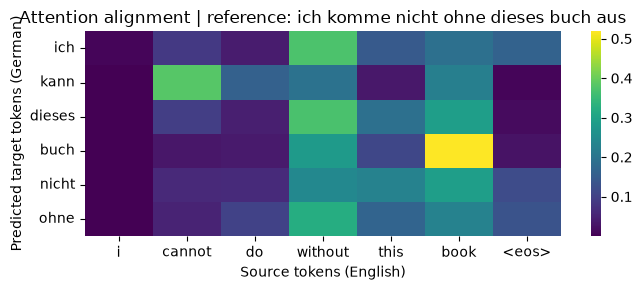

Source: i cannot do without this book
Reference: ich komme nicht ohne dieses buch aus
Prediction: ich kann dieses buch nicht ohne
--------------------------------------------------------------------------------


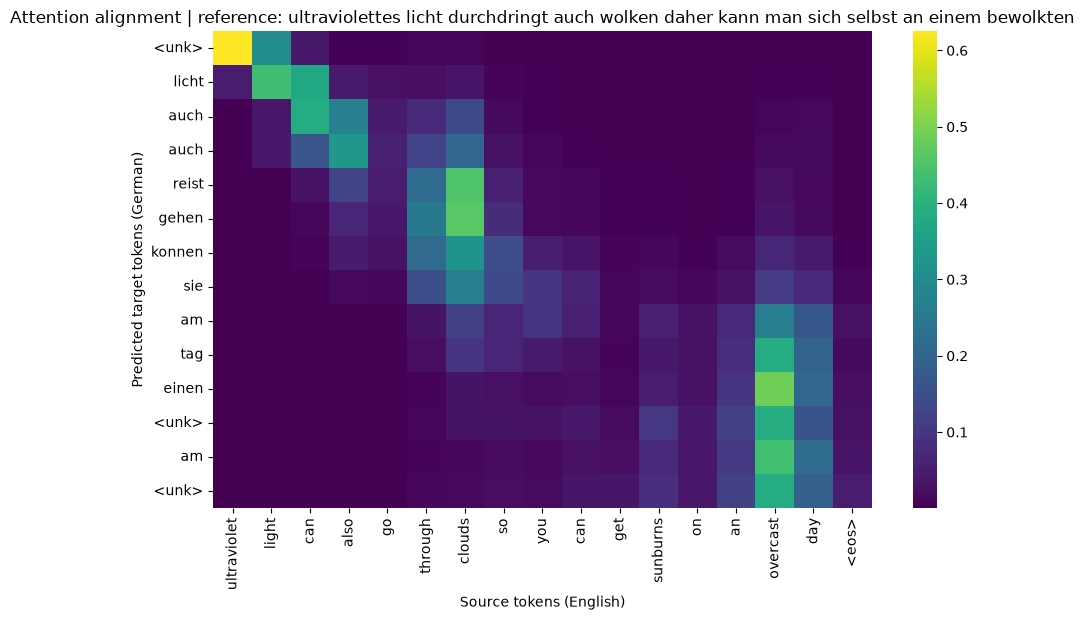

Source: ultraviolet light can also go through clouds so you can get sunburns on an overcast day
Reference: ultraviolettes licht durchdringt auch wolken daher kann man sich selbst an einem bewolkten tag einen sonnenbrand holen
Prediction: <unk> licht auch auch reist gehen konnen sie am tag einen <unk> am <unk>
--------------------------------------------------------------------------------


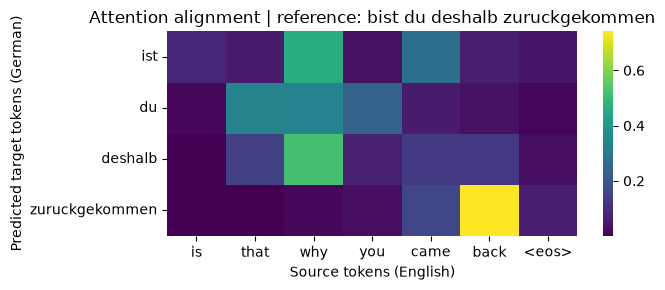

Source: is that why you came back
Reference: bist du deshalb zuruckgekommen
Prediction: ist du deshalb zuruckgekommen
--------------------------------------------------------------------------------


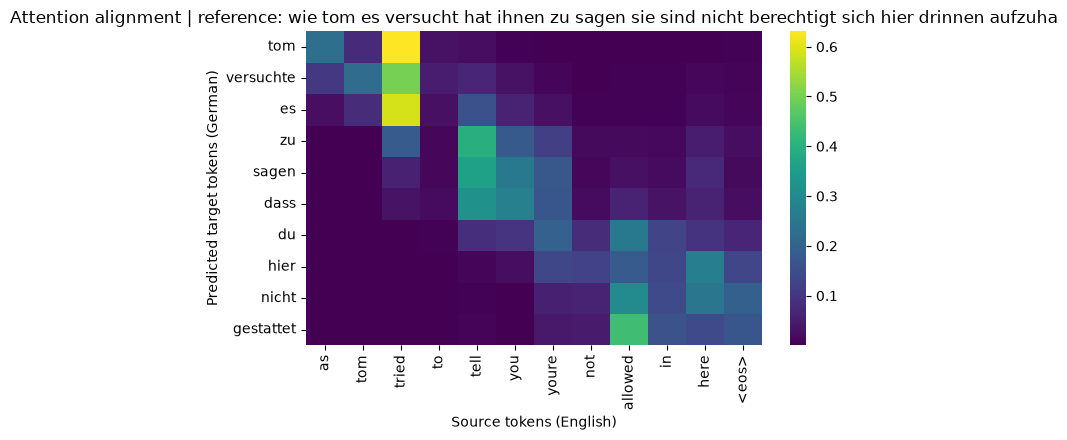

Source: as tom tried to tell you youre not allowed in here
Reference: wie tom es versucht hat ihnen zu sagen sie sind nicht berechtigt sich hier drinnen aufzuhalten
Prediction: tom versuchte es zu sagen dass du hier nicht gestattet
--------------------------------------------------------------------------------


In [ ]:
# Choose varied held-out examples, including long examples when available.
heat_df=test_df.copy()
heat_df["length"]=heat_df.ENGLISH.str.split().str.len()
chosen=[]
for condition in [
    heat_df.length.between(3,6),
    heat_df.length.between(12,18),
  
    heat_df.ENGLISH.str.contains(r"\b(?:why|when|because|that)\b", regex=True), 
    heat_df.length.ge(9),
]:
    candidates=heat_df[condition & ~heat_df.index.isin(chosen)]
    if len(candidates): chosen.append(candidates.index[0])
chosen=list(dict.fromkeys(chosen))[:4]
for idx in chosen:
    row=heat_df.loc[idx]
    pred,src_tokens,tgt_tokens,weights=translate_attention(attention_model,row.ENGLISH,return_attention=True)
    if weights.size:
        plt.figure(figsize=(max(7,len(src_tokens)*.55),max(3,len(tgt_tokens)*.45)))
        sns.heatmap(weights,xticklabels=src_tokens,yticklabels=tgt_tokens,cmap="viridis")
        plt.xlabel("Source tokens (English)"); plt.ylabel("Predicted target tokens (German)")
        plt.title(f"Attention alignment | reference: {row.GERMAN[:90]}")
        plt.tight_layout(); plt.show()
    print("Source:",row.ENGLISH)
    print("Reference:",row.GERMAN)
    print("Prediction:",pred)
    print("-"*80)

### Attention Heatmap Analysis

The heatmaps reveal varying alignment patterns depending on sentence complexity and the presence of OOV (Out-of-Vocabulary) tokens:

1. **Monotonic Alignment & Reordering:** In sentences with standard SVO structure (e.g., "is that why you came back"), the attention mechanism shows clear diagonal alignments. However, for German verb-final clauses, we observe strong **off-diagonal jumps**. For instance, in the third heatmap, the German participle `zuruckgekommen` correctly places maximum attention on the English word `back`, demonstrating the model's ability to learn long-range reordering.

2. **Failure Cases & OOV Breakdown:** As seen in the second heatmap (long sentence), the presence of unknown words (`<unk>`) severely disrupts the attention weights. The model loses alignment, resulting in repetitions (`auch auch`) and dropped content. In the fourth heatmap, while the early words align perfectly, the model loses track at the end of the clause, failing to translate "allowed in".

3. **Word-order Reordering:** In the first heatmap ("i cannot do without this book"), the model successfully aligns `buch` with `book`, but the reordering of the negation and preposition causes a scattered attention distribution, resulting in an incorrect grammatical structure in German.

## 12. Qualitative error analysis — 8 held-out examples



In [15]:
qual_rows=[]
sample=test_df.sample(min(8,len(test_df)),random_state=SEED)
for row in sample.itertuples(index=False):
    bp=translate_baseline(baseline,row.ENGLISH)
    ap=translate_attention(attention_model,row.ENGLISH)
    
    qual_rows.append({"Source":row.ENGLISH,"Reference":row.GERMAN,
                      "Baseline":bp,"Attention":ap})
qualitative=pd.DataFrame(qual_rows)
display(qualitative)
qualitative.to_csv("qualitative_examples.csv",index=False)

,Source,Reference,Baseline,Attention
0,can you stand,kannst du stehen,kannst du aufstehen,kannst du stehen
1,we sang while hiking,wir sangen beim wandern,wir sangen nach wandern,wir sangen uns wandern
2,are you here alone,bist du allein hier,bist du hier allein,bist du allein hier
3,im trying to be happy,ich versuche glucklich zu sein,ich versuche glucklich zu sein,ich versuche glucklich zu sein
4,i liked your story,deine geschichte hat mir gefallen,deine geschichte gefiel mir freude,ich gefiel deine geschichte
5,owing to the bad weather the game was put off,wegen des schlechten wetters wurde das spiel v...,spiel spiel das spiel wetter wetter,das das schlechten schlechten wetter das das w...
6,dont let tom near my kids,lasst tom nicht in die nahe meiner kinder,lass tom nicht in meine kinder nahe,lass tom nicht in nahe meiner nahe meiner nahe
7,tom offered to carry marys suitcase but she to...,tom bot maria an dass er ihren koffer truge da...,tom schrieb maria zu zu sagen aber sie darf si...,tom erbot maria koffer den koffer zu sagen abe...


## Qualitative Error Analysis:
Manual inspection of the 8 test examples reveals several recurring error types:

# 1. Dropped Content & Repetition:
 On long sentences (Examples 5, 6, 7), both models struggle to maintain coherence. The Baseline completely collapses on Example 5, losing the main clause and repeating "spiel" and "wetter". The Attention model also shows repetition in Examples 6 and 7 (repeating "nahe meiner" and "koffer"), but generally retains more context than the baseline.

# 2.Lexical and Grammatical Errors:
 The Baseline frequently makes incorrect lexical choices (e.g., translating "stand" as "aufstehen" instead of "stehen" in Ex 0) and preposition errors. The Attention model makes fewer content-word errors but struggles with complex German grammar (e.g., incorrect pronoun "uns" in Ex 1, or word order in Ex 4).

# 3.OOV / Unknown Tokens:
 While no explicit <unk> tokens appeared in these specific 8 examples, both models clearly fail on out-of-vocabulary concepts (e.g., "marys suitcase").

In conclusion, while Attention significantly improves alignment and prevents the complete information loss seen in the baseline's long-sentence failures, it does not eliminate grammatical (gender/case/agreement) errors, which remain a challenge due to the limited training data and model capacity.



## 14. Save artifacts and reproducibility metadata

In [16]:
import pickle

os.makedirs("artifacts",exist_ok=True)
torch.save(baseline.state_dict(),"artifacts/baseline_lstm.pt")
torch.save(attention_model.state_dict(),"artifacts/attention_lstm.pt")


with open("artifacts/src_vocab.pkl","wb") as f: pickle.dump(src_vocab.itos,f)
with open("artifacts/tgt_vocab.pkl","wb") as f: pickle.dump(tgt_vocab.itos,f)

with open("artifacts/run_config.json","w") as f:
    json.dump({"seed":SEED,"max_len":MAX_LEN,"batch_size":BATCH_SIZE,"embedding_dim":EMB_DIM,
               "hidden_dim":HID_DIM,"epochs":EPOCHS,"learning_rate":LEARNING_RATE,
               "teacher_forcing":TEACHER_FORCING,"device":str(DEVICE),
               "train_size":len(train_df),"validation_size":len(val_df),"test_size":len(test_df)},f,indent=2)
print("Saved checkpoints, vocabularies, evaluation CSVs, and run configuration.")

Saved checkpoints, vocabularies, evaluation CSVs, and run configuration.
